# Global Solution 2026.2 — Machine Learning & Modelling
## HEIMDALL | Previsão da umidade do solo para as próximas 24 horas

**Equipe:** Adalberto Alves Cruz - RM574115 | Danilo Keithi Makiya Nakasone - RM574137 | Gustavo da Silva Nascimento - RM570821
**Público:** pequenos produtores rurais  
**Objetivo:** prever a umidade do solo a 10 cm de profundidade **24 horas depois da medição atual**, para ajudar a planejar a irrigação e evitar perdas.

**Base real:** CEMADEN, disponível no [Mendeley Data](https://data.mendeley.com/datasets/xrk5rfcpvg/2) (DOI: 10.17632/xrk5rfcpvg.2). Utilizamos os arquivos `PCDs_.zip` e `_Stations(1).xlsx` enviados pelo grupo.

**O que este notebook contém:** análise dos dados, tratamento de valores ausentes, histórico de umidade e chuva, separação temporal, baseline, **dois algoritmos** (Ridge e Random Forest), busca de parâmetros, métricas, importância das variáveis e exemplo de aplicação.


## 1. Bibliotecas e arquivos

Bibliotecas necessárias para o funcionamento do código e conexão com o Google Drive para os arquivos.

In [2]:
import io
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from IPython.display import display

pastas = [Path.cwd(), Path('/content'), Path('/mnt/data'),
          Path('/content/drive/MyDrive/Colab Notebooks')]

if not any((p / 'PCDs_.zip').exists() for p in pastas):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass

pasta = next((p for p in pastas if (p / 'PCDs_.zip').exists()), None)
if pasta is None:
    raise FileNotFoundError('Coloque PCDs_.zip ao lado do notebook ou no Google Drive.')

arquivo_zip = pasta / 'PCDs_.zip'
arquivo_estacoes = pasta / '_Stations(1).xlsx'
if not arquivo_estacoes.exists():
    arquivo_estacoes = pasta / '_Stations.xlsx'

print('ZIP:', arquivo_zip)
print('Estações:', arquivo_estacoes)

Mounted at /content/drive
ZIP: /content/drive/MyDrive/Colab Notebooks/PCDs_.zip
Estações: /content/drive/MyDrive/Colab Notebooks/_Stations.xlsx


## 2. Conhecendo a base

A planilha de estações contém 360 locais. Para deixar o treinamento leve, selecionamos **uma estação por estado (até 9)** de forma reproduzível, com `random_state=42`. Se alguma estação não tiver dados suficientes, será descartada.

In [3]:
estacoes = pd.read_excel(arquivo_estacoes)
selecionadas = estacoes.groupby('State', group_keys=False).sample(n=1, random_state=42)
print('Estações disponíveis:', len(estacoes))
print('Estações selecionadas:', len(selecionadas))
display(selecionadas[['Filename', 'City', 'State']].head(10))

Estações disponíveis: 360
Estações selecionadas: 9


,Filename,City,State
326,PCD_Agro_AL_270500201U.xlsx,Mata Grande,AL
79,PCD_Acqua_BA_291960301C.xlsx,Macajuba,BA
163,PCD_Acqua_CE_230835101C.xlsx,Milhã,CE
193,PCD_Acqua_MG_313400401C.xlsx,Itinga,MG
229,PCD_Acqua_PB_251380201C.xlsx,Santa Teresinha,PB
354,PCD_Agro_PE_261400601U.xlsx,Serrita,PE
357,PCD_Agro_PI_220790001U.xlsx,Pedro Ii,PI
314,PCD_Acqua_RN_240830001C.xlsx,Nova Cruz,RN
324,PCD_Acqua_SE_280570301C.xlsx,Propriá,SE


## 3. Preparação dos dados e previsão de 24 horas

Cada planilha contém leituras horárias (`Time`, `US10cm`, `US20cm`, `Precip`) e informações sobre o solo (`Sand`, `Clay`).

- `US10cm` e `US20cm` são **umidade volumétrica** em m³/m³ (por exemplo, `0.15` equivale a 15% de volume).
- `Precip` é a chuva acumulada na última hora, em milímetros.
- Os metadados `Sand` e `Clay` representam gramas por 1 kg de solo; dividimos por 10 para obter porcentagem.
- **Não inventamos leituras ausentes**: criamos uma sequência horária regular e removemos exemplos incompletos.
- O valor que queremos prever será `US10cm` **24 horários depois** (`shift(-24)`), não simplesmente o próximo registro.

In [4]:
ATRIBUTOS = [
    'umidade_atual', 'umidade_20cm',
    'umidade_6h_atras', 'umidade_12h_atras', 'umidade_24h_atras',
    'media_umidade_24h', 'chuva_24h',
    'hora', 'mes', 'areia_pct', 'argila_pct'
]
ALVO = 'umidade_em_24h'

series = []
qualidade = []

with zipfile.ZipFile(arquivo_zip) as zip_dados:
    nomes_zip = {Path(n).name: n for n in zip_dados.namelist() if n.endswith('.xlsx')}

    for _, estacao in selecionadas.iterrows():
        nome = estacao['Filename']
        if nome not in nomes_zip:
            continue

        excel = pd.ExcelFile(io.BytesIO(zip_dados.read(nomes_zip[nome])))
        dados = pd.read_excel(excel, 'Data', usecols=['Time', 'Precip', 'US10cm', 'US20cm'])
        info = pd.read_excel(excel, 'Info', header=None)
        meta = dict(zip(info[0], info[1]))
        areia = pd.to_numeric(meta.get('Sand'), errors='coerce')
        argila = pd.to_numeric(meta.get('Clay'), errors='coerce')
        if pd.isna(areia) or pd.isna(argila):
            continue

        # Colocar os dados em ordem e respeitar intervalos horários.
        dados['Time'] = pd.to_datetime(dados['Time'], errors='coerce')
        dados = (dados.dropna(subset=['Time'])
                      .drop_duplicates('Time')
                      .sort_values('Time')
                      .set_index('Time')
                      .asfreq('h'))

        # Leituras fisicamente impossíveis passam a ser valores ausentes.
        for coluna, maximo in [('Precip', 350), ('US10cm', 0.70), ('US20cm', 0.70)]:
            dados[coluna] = pd.to_numeric(dados[coluna], errors='coerce')
            dados[coluna] = dados[coluna].where(dados[coluna].between(0, maximo))

        qualidade.append({
            'estacao': nome,
            'ausentes_umidade_10cm_pct': dados['US10cm'].isna().mean() * 100,
            'ausentes_chuva_pct': dados['Precip'].isna().mean() * 100
        })

        dados['umidade_atual'] = dados['US10cm']
        dados['umidade_20cm'] = dados['US20cm']
        for horas in (6, 12, 24):
            dados[f'umidade_{horas}h_atras'] = dados['US10cm'].shift(horas)

        dados['media_umidade_24h'] = dados['US10cm'].rolling(24, min_periods=18).mean()
        dados['chuva_24h'] = dados['Precip'].rolling(24, min_periods=18).sum()
        dados['hora'] = dados.index.hour
        dados['mes'] = dados.index.month
        dados['areia_pct'] = areia / 10
        dados['argila_pct'] = argila / 10
        dados[ALVO] = dados['US10cm'].shift(-24)

        # Usar uma leitura a cada 6 horas mantém o treinamento mais rápido.
        dados = dados[dados.index.hour.isin([0, 6, 12, 18])]
        dados = dados.dropna(subset=ATRIBUTOS + [ALVO])
        if len(dados) < 150:
            continue

        dados = dados[ATRIBUTOS + [ALVO]].copy()
        dados['data_hora'] = dados.index
        dados['estacao'] = nome
        series.append(dados.reset_index(drop=True))

if len(series) < 5:
    raise ValueError('Poucas estações válidas. Confira os arquivos da base.')

base = pd.concat(series, ignore_index=True).sort_values('data_hora').reset_index(drop=True)
print('Estações utilizadas:', len(series))
print('Exemplos válidos:', len(base))
print('Período (UTC):', base['data_hora'].min(), 'até', base['data_hora'].max())
display(base[['data_hora', 'umidade_atual', 'chuva_24h', ALVO]].head())

Estações utilizadas: 9
Exemplos válidos: 18280
Período (UTC): 2015-07-02 18:00:00 até 2019-04-29 18:00:00


,data_hora,umidade_atual,chuva_24h,umidade_em_24h
0,2015-07-02 18:00:00,0.038,0.0,0.037
1,2015-07-16 18:00:00,0.050,0.2,0.050
2,2015-07-17 18:00:00,0.050,0.0,0.050
3,2015-07-18 06:00:00,0.050,0.0,0.050
4,2015-07-18 12:00:00,0.050,0.0,0.050


## 4. Análise exploratória (EDA)

Vamos observar a distribuição dos dados, os valores ausentes nas estações originais e como a umidade evolui no tempo.

,umidade_atual,umidade_20cm,chuva_24h,umidade_em_24h
count,18280.000,18280.000,18280.000,18280.000
mean,0.066,0.087,1.223,0.066
std,0.046,0.051,5.625,0.047
min,0.000,0.000,0.000,0.000
25%,0.040,0.050,0.000,0.040
50%,0.056,0.070,0.000,0.054
75%,0.080,0.120,0.000,0.080
max,0.320,0.400,114.200,0.320


,ausentes_umidade_10cm_pct,ausentes_chuva_pct
count,9.0,9.0
mean,47.7,16.4
std,25.7,20.6
min,6.6,0.7
25%,33.1,7.3
50%,42.7,13.7
75%,64.6,15.7
max,94.1,68.7


Valores ausentes após a limpeza: 0
Registros duplicados (estação + horário): 0


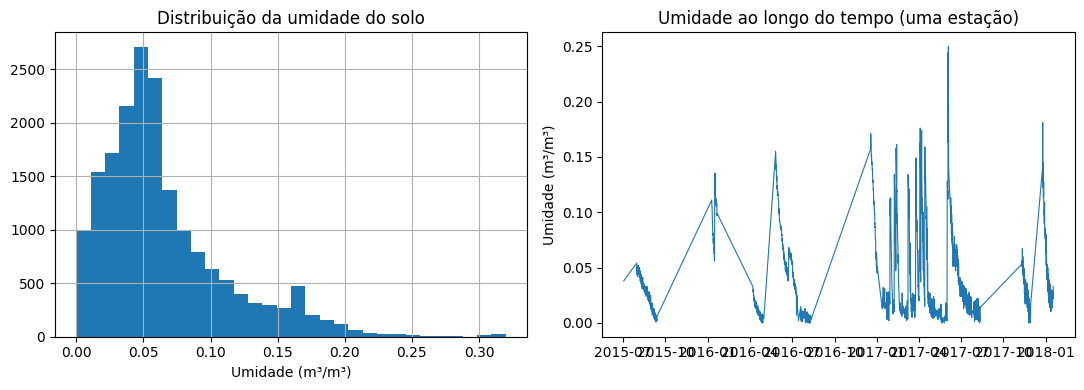

,umidade_atual,umidade_20cm,chuva_24h,umidade_em_24h
umidade_atual,1.00,0.72,0.34,0.95
umidade_20cm,0.72,1.00,0.26,0.68
chuva_24h,0.34,0.26,1.00,0.36
umidade_em_24h,0.95,0.68,0.36,1.00


Interpretação: leituras próximas no tempo costumam ser semelhantes;
por isso, precisamos comparar os modelos com a persistência.


In [5]:
display(base[['umidade_atual', 'umidade_20cm', 'chuva_24h', ALVO]].describe().round(3))
display(pd.DataFrame(qualidade).describe().round(1))
print('Valores ausentes após a limpeza:', int(base[ATRIBUTOS + [ALVO]].isna().sum().sum()))
print('Registros duplicados (estação + horário):', int(base.duplicated(['estacao', 'data_hora']).sum()))

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
base['umidade_atual'].hist(bins=30, ax=eixos[0])
eixos[0].set(title='Distribuição da umidade do solo', xlabel='Umidade (m³/m³)')

uma_estacao = base[base['estacao'] == base['estacao'].iloc[0]].sort_values('data_hora')
eixos[1].plot(uma_estacao['data_hora'], uma_estacao['umidade_atual'], linewidth=0.8)
eixos[1].set(title='Umidade ao longo do tempo (uma estação)', ylabel='Umidade (m³/m³)')
plt.tight_layout()
plt.show()

correlacoes = base[['umidade_atual', 'umidade_20cm', 'chuva_24h', ALVO]].corr()
display(correlacoes.round(2))
print('Interpretação: leituras próximas no tempo costumam ser semelhantes;')
print('por isso, precisamos comparar os modelos com a persistência.')

### O que mostram os gráficos exploratórios?

- **Histograma (à esquerda):** a maioria das medições apresenta umidade baixa. A mediana da amostra foi **0,056 m³/m³** (5,6% em volume), mas essa condição depende da estação e do período analisados.
- **Umidade ao longo do tempo (à direita):** na estação ilustrada, a umidade sobe e desce em diferentes momentos. Isso mostra por que o histórico do sensor é útil para prever mudanças futuras.

**Observação sobre os dados:** antes da limpeza, as 9 estações tinham em média **47,7% de leituras ausentes** para umidade a 10 cm. Removemos exemplos incompletos em vez de preencher valores futuros, reduzindo a base disponível para treinamento.

## 5. Separação de treino e teste

Usamos as **datas**, em ordem cronológica: cerca de 80% do período para treinamento e 20% para teste. Deixamos um intervalo de 24 horas entre os dois, porque o alvo do último registro de treino usa uma leitura do dia seguinte. Isso evita usar respostas do período de teste no treinamento.

In [6]:
dias = np.sort(base['data_hora'].dt.normalize().unique())
data_corte = pd.Timestamp(dias[int(len(dias) * 0.80)])

# Reservar as últimas datas para teste e deixar 24h de separação.
treino = base[base['data_hora'] < data_corte - pd.Timedelta(hours=24)]
teste = base[base['data_hora'] >= data_corte]

X_treino, y_treino = treino[ATRIBUTOS], treino[ALVO]
X_teste, y_teste = teste[ATRIBUTOS], teste[ALVO]
print('Treino:', len(treino), 'registros')
print('Teste:', len(teste), 'registros')
print('Início do teste:', data_corte)
assert treino['data_hora'].max() + pd.Timedelta(hours=24) < teste['data_hora'].min()

Treino: 16065 registros
Teste: 2203 registros
Início do teste: 2018-07-29 00:00:00


## 6. Modelos de Machine Learning

**Baseline de persistência:** adivinhar que a umidade depois de 24h será igual à de agora.  
**Ridge:** regressão linear que aprende uma relação entre as variáveis; usa `StandardScaler` dentro de um `Pipeline`.  
**Random Forest:** conjunto de árvores que encontra relações não lineares sem precisar padronizar as entradas.

Primeiro comparamos os dois algoritmos em uma validação no final do período de treino, **sem olhar o teste**. O melhor será otimizado na próxima etapa.

In [7]:
modelos = {
    'Ridge': make_pipeline(StandardScaler(), Ridge()),
    'Random Forest': RandomForestRegressor(n_estimators=60, max_depth=12,
                                          min_samples_leaf=2, random_state=42, n_jobs=-1)
}

# Separar uma parte final do treinamento para escolher o algoritmo.
dias_treino = np.sort(treino['data_hora'].dt.normalize().unique())
data_validacao = pd.Timestamp(dias_treino[int(len(dias_treino) * 0.80)])
subtreino = treino[treino['data_hora'] < data_validacao - pd.Timedelta(hours=24)]
validacao = treino[treino['data_hora'] >= data_validacao]

resultados_validacao = []
for nome, modelo in modelos.items():
    modelo.fit(subtreino[ATRIBUTOS], subtreino[ALVO])
    previsao = modelo.predict(validacao[ATRIBUTOS])
    rmse = np.sqrt(mean_squared_error(validacao[ALVO], previsao))
    resultados_validacao.append({'Modelo': nome, 'RMSE validação': rmse})

resultado_val = pd.DataFrame(resultados_validacao).sort_values('RMSE validação')
display(resultado_val.round(5))
melhor_nome = resultado_val.iloc[0]['Modelo']
print('Modelo escolhido antes do teste:', melhor_nome)

,Modelo,RMSE validação
0,Ridge,0.01981
1,Random Forest,0.02561


Modelo escolhido antes do teste: Ridge


## 7. Melhoria do modelo (GridSearchCV)

O `GridSearchCV` testa poucos valores de parâmetros. O `TimeSeriesSplit` faz **cinco validações temporais**: cada treinamento acontece antes da respectiva validação.

Como o dataset combina muitas estações no mesmo horário, criamos as divisões por **dia**, deixando 24 horas de intervalo. Não usamos validação aleatória.

In [8]:
# Criar os cinco grupos de treino/validação por datas, sem misturar futuro com passado.
partes_cv = []
for indices_treino, indices_val in TimeSeriesSplit(n_splits=5).split(dias_treino):
    inicio_val = pd.Timestamp(dias_treino[indices_val[0]])
    fim_val = pd.Timestamp(dias_treino[indices_val[-1]]) + pd.Timedelta(days=1)
    pos_treino = np.where(treino['data_hora'].values < (inicio_val - pd.Timedelta(hours=24)))[0]
    pos_val = np.where((treino['data_hora'].values >= inicio_val) &
                       (treino['data_hora'].values < fim_val))[0]
    partes_cv.append((pos_treino, pos_val))

# Testar poucos valores para ficar rápido e simples de entender.
if melhor_nome == 'Ridge':
    parametros = {'ridge__alpha': [0.1, 1, 10, 100]}
else:
    parametros = {'n_estimators': [40, 60], 'max_depth': [8, 12]}

busca = GridSearchCV(modelos[melhor_nome], parametros, cv=partes_cv,
                     scoring='neg_root_mean_squared_error', n_jobs=1)
busca.fit(X_treino, y_treino)
modelo_final = busca.best_estimator_
print('Modelo otimizado:', melhor_nome)
print('Melhores parâmetros:', busca.best_params_)
print('RMSE médio da validação temporal:', round(-busca.best_score_, 5))

Modelo otimizado: Ridge
Melhores parâmetros: {'ridge__alpha': 10}
RMSE médio da validação temporal: 0.01583


## 8. Comparação de métricas e overfitting

**MAE:** erro absoluto médio; **RMSE:** erro quadrático médio (quanto menor, melhor); **R²:** quanto maior, melhor em geral. Todas as métricas de erro estão em **m³/m³**. Avaliamos **treino e teste** para observar a generalização.

,Modelo,MAE treino,MAE teste,RMSE treino,RMSE teste,R2 treino,R2 teste
0,Baseline (persistência),0.00537,0.00666,0.01546,0.01426,0.88956,0.90683
1,Ridge,0.00593,0.00683,0.01498,0.01329,0.89633,0.91906
2,Random Forest,0.00392,0.00728,0.00978,0.01417,0.95577,0.90803
3,Modelo otimizado,0.00593,0.00683,0.01498,0.01329,0.89631,0.91913



Interpretação:
Não há grande aumento relativo do RMSE no teste; ainda assim, a validação em campo é necessária.
O modelo otimizado superou a persistência no teste.


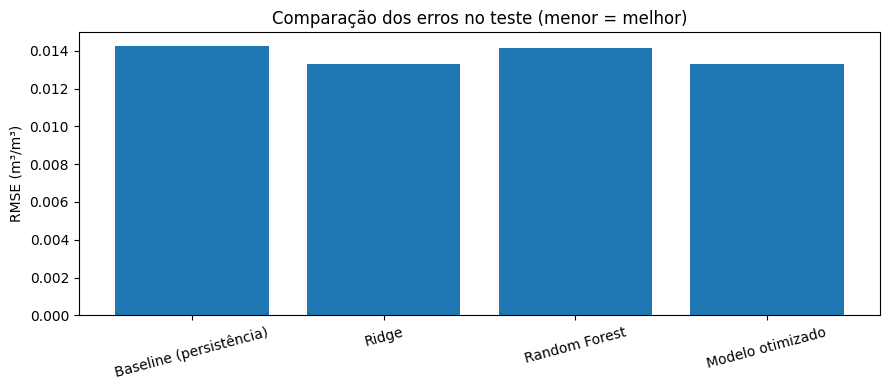

In [9]:
def calcular_metricas(real, previsto):
    return (mean_absolute_error(real, previsto),
            np.sqrt(mean_squared_error(real, previsto)),
            r2_score(real, previsto))

resultado = []
previsoes = {}

# Baseline: prevê a mesma umidade que foi medida agora.
modelos_avaliados = {'Baseline (persistência)': None, **modelos,
                    'Modelo otimizado': modelo_final}

for nome, modelo in modelos_avaliados.items():
    if modelo is None:
        previsto_treino = X_treino['umidade_atual']
        previsto_teste = X_teste['umidade_atual']
    else:
        modelo.fit(X_treino, y_treino)
        previsto_treino = modelo.predict(X_treino)
        previsto_teste = modelo.predict(X_teste)

    mae_tr, rmse_tr, r2_tr = calcular_metricas(y_treino, previsto_treino)
    mae_te, rmse_te, r2_te = calcular_metricas(y_teste, previsto_teste)
    resultado.append([nome, mae_tr, mae_te, rmse_tr, rmse_te, r2_tr, r2_te])
    previsoes[nome] = previsto_teste

tabela = pd.DataFrame(resultado, columns=[
    'Modelo', 'MAE treino', 'MAE teste', 'RMSE treino', 'RMSE teste', 'R2 treino', 'R2 teste'
])
display(tabela.round(5))

linha_final = tabela[tabela['Modelo'] == 'Modelo otimizado'].iloc[0]
linha_base = tabela[tabela['Modelo'] == 'Baseline (persistência)'].iloc[0]
print('\nInterpretação:')
if linha_final['RMSE teste'] > linha_final['RMSE treino'] * 1.5:
    print('Possível overfitting: erro de teste muito maior que o de treino.')
else:
    print('Não há grande aumento relativo do RMSE no teste; ainda assim, a validação em campo é necessária.')
if linha_final['RMSE teste'] < linha_base['RMSE teste']:
    print('O modelo otimizado superou a persistência no teste.')
else:
    print('O baseline foi melhor: o modelo ainda precisa ser aperfeiçoado.')

plt.figure(figsize=(9, 4))
plt.bar(tabela['Modelo'], tabela['RMSE teste'])
plt.title('Comparação dos erros no teste (menor = melhor)')
plt.ylabel('RMSE (m³/m³)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### O que mostra o gráfico de comparação dos modelos?

Cada barra representa o **RMSE no teste**: **quanto menor a barra, menor o erro quadrático médio** da previsão. O **Ridge otimizado (0,01329 m³/m³)** apresentou RMSE menor que o **baseline de persistência (0,01426 m³/m³)** e que o **Random Forest (0,01417 m³/m³)**. A redução do RMSE em relação ao baseline foi de cerca de **6,8%**.

Na tabela, vale observar também o comportamento de treino e teste: o Random Forest teve erro de treino bem menor do que o de teste, o que sugere *overfitting*. Já o Ridge apresentou uma diferença menor. **Ressalva:** o baseline teve MAE de teste ligeiramente melhor que o Ridge, então o resultado depende da métrica escolhida.

## 9. Importância das variáveis

O método de **permutação** embaralha uma variável de cada vez e mede quanto o modelo piora. Quanto maior a importância, maior a contribuição daquela variável **neste modelo e conjunto de dados**. Variáveis correlacionadas podem dividir importância entre si.

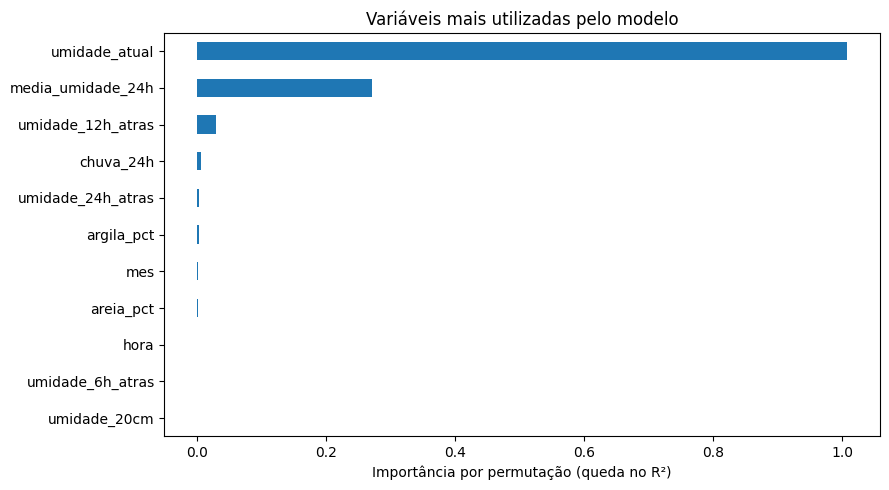

Variável com maior importância: umidade_atual


In [10]:
# Usamos uma amostra pequena do teste para executar rapidamente.
amostra = X_teste.sample(n=min(300, len(X_teste)), random_state=42)
importancia = permutation_importance(modelo_final, amostra, y_teste.loc[amostra.index],
                                     n_repeats=2, random_state=42)
importancias = pd.Series(importancia.importances_mean, index=ATRIBUTOS).sort_values()

plt.figure(figsize=(9, 5))
importancias.plot.barh()
plt.xlabel('Importância por permutação (queda no R²)')
plt.title('Variáveis mais utilizadas pelo modelo')
plt.tight_layout()
plt.show()
print('Variável com maior importância:', importancias.index[-1])

### O que mostra o gráfico de importância das variáveis?

O gráfico indica quais dados fizeram mais diferença para as previsões do **Ridge otimizado**, segundo um teste chamado **importância por permutação**. A **umidade atual** foi a variável mais importante, seguida da **média de umidade das últimas 24 horas**. Isso é coerente com a ideia de que a condição atual e o histórico recente ajudam a prever a condição futura do solo.

As demais variáveis tiveram importância menor **nesta amostra e neste modelo**. Como algumas variáveis são parecidas ou correlacionadas, esse gráfico **não prova uma relação de causa e efeito**.

## 10. Exemplo de aplicação no Heimdall

O dispositivo AICSS envia um JSON com `umidade`, `temperatura`, `nivel_reservatorio` etc. **Mas ele ainda não envia** histórico a 10/20 cm, chuva e composição do solo; o potenciômetro do Wokwi também não substitui um sensor calibrado.

Por isso, a função abaixo recebe o JSON **e** um contexto histórico (das medições reais de teste). Sem o histórico, ela explica que faltam dados. O resultado é **uma recomendação didática**, não um comando real para ligar a bomba.

In [11]:
def simular_decisao_rega(json_esp32, historico=None):
    if historico is None:
        return {'status': 'DADOS_INSUFICIENTES',
                'mensagem': 'Faltam histórico de umidade, chuva e características do solo.'}

    if json_esp32['nivel_reservatorio'] < 20:
        return {'status': 'BLOQUEIO', 'recomendacao': 'Não ligar a bomba: reservatório baixo.'}

    # O JSON do exemplo vem de uma linha real do CEMADEN (mesma escala).
    entrada = pd.DataFrame([historico])[ATRIBUTOS].copy()
    entrada['umidade_atual'] = float(json_esp32['umidade']) / 100
    previsao_pct = float(modelo_final.predict(entrada)[0]) * 100

    if previsao_pct < 20:
        recomendacao = 'Solo pode ficar muito seco: avaliar irrigação.'
    elif previsao_pct < 35:
        recomendacao = 'Monitorar a umidade e a janela tarifária.'
    else:
        recomendacao = 'Umidade prevista adequada: continuar monitorando.'

    return {'umidade_prevista_24h_pct': round(previsao_pct, 2),
            'recomendacao': recomendacao, 'bomba_acionada': False}

# Exemplo coerente: valores do JSON e do histórico vêm da mesma estação.
exemplo = teste.iloc[0]
json_exemplo = {
    'id_sensor': 'S01', 'fazenda': 'Sitio Boa Esperanca', 'cultivo': 'Tomate',
    'umidade': float(exemplo['umidade_atual']) * 100,
    'temperatura': 28.0, 'nivel_reservatorio': 75.0,
    'data_hora': str(exemplo['data_hora'])
}
historico = exemplo[ATRIBUTOS].to_dict()

print('Somente JSON:', simular_decisao_rega(json_exemplo))
print('JSON + histórico:', simular_decisao_rega(json_exemplo, historico))

json_reservatorio_baixo = dict(json_exemplo)
json_reservatorio_baixo['nivel_reservatorio'] = 10.0
print('Reservatório baixo:', simular_decisao_rega(json_reservatorio_baixo, historico))

Somente JSON: {'status': 'DADOS_INSUFICIENTES', 'mensagem': 'Faltam histórico de umidade, chuva e características do solo.'}
JSON + histórico: {'umidade_prevista_24h_pct': 4.3, 'recomendacao': 'Solo pode ficar muito seco: avaliar irrigação.', 'bomba_acionada': False}
Reservatório baixo: {'status': 'BLOQUEIO', 'recomendacao': 'Não ligar a bomba: reservatório baixo.'}


## 11. Conclusão e limitações

Neste trabalho, utilizamos **18.280 registros válidos de 9 estações do CEMADEN** para prever a umidade volumétrica do solo a **10 cm de profundidade, 24 horas à frente**. Comparamos um baseline de persistência, o modelo Ridge e o Random Forest, respeitando a ordem temporal na separação dos dados e na validação.

O **Ridge otimizado** foi escolhido pela validação temporal, com `alpha = 10`. No conjunto de teste, alcançou **RMSE de 0,01329 m³/m³** e **R² de 0,91913**. O baseline apresentou RMSE de **0,01426 m³/m³**, portanto o Ridge reduziu esse erro em cerca de **6,8%**. Por outro lado, o baseline teve **MAE ligeiramente menor** (**0,00666** contra **0,00683 m³/m³** do Ridge); por isso, não podemos dizer que o Ridge foi melhor em todas as métricas.

O **Random Forest** obteve RMSE de **0,00978** no treino e **0,01417** no teste, diferença que indica possível *overfitting*. O Ridge teve comportamento mais estável, embora esses resultados ainda não comprovem que o modelo funcionará igualmente bem em qualquer propriedade rural.

A análise de importância mostrou que **a umidade atual e a média das últimas 24 horas** são as variáveis com maior contribuição para as previsões desse modelo. Na demonstração, o sistema estimou **4,3% de umidade para as próximas 24 horas** em um exemplo do conjunto de teste e sugeriu avaliar a irrigação; também bloqueou a recomendação de acionamento quando o reservatório estava baixo. **A aplicação é demonstrativa:** o notebook não aciona uma bomba real.

**Conclusão:** os resultados indicam que o Machine Learning pode ajudar no planejamento da irrigação, permitindo observar o risco de ressecamento antes que ele ocorra. Porém, **não medimos economia efetiva de água, energia ou redução de perdas agrícolas** nesta atividade.

**Limitações e melhorias futuras:**
- Os dados vieram de apenas **9 das 360 estações** disponíveis na planilha, e havia uma média de **47,7% de leituras ausentes de umidade a 10 cm** nas estações selecionadas antes da limpeza.
- Os modelos ainda precisam ser testados com sensores físicos calibrados e em novas propriedades rurais.
- Os limites de **20% e 35%** usados na simulação são critérios didáticos do grupo, não recomendações agronômicas universais.
- O JSON do ESP32 **não fornece, sozinho, todas as entradas** do modelo (como histórico, chuva e composição do solo). A conexão completa é uma etapa futura.

**ODS relacionados:** ODS 2 (Fome Zero e Agricultura Sustentável), ODS 6 (Água Potável e Saneamento), ODS 9 (Indústria, Inovação e Infraestrutura) e ODS 12 (Consumo e Produção Responsáveis).
